## Description
This notebook generates visualizations and outputs them to results/visualisations to better understand how the model results come about. It is structured like:
1. Imports
2. Load networks
3. Set technology colors for some visualisations
4. A first look at model outputs (energy balances)
5. Examining industrial low-to-medium heat demand provision
6. Examining emissions
7. Examining electricity demand and supply

### 1) Imports

In [ ]:
from pathlib import Path
import textwrap
import re
import warnings
import math
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

years = [2020, 2030, 2040, 2050]

# Import the public function from the package you completed
from energy_model.postprocessing import (
    annual_emissions,
    integrate_annual_rates,
)

### 2) Load networks

In [11]:
RESULTS_DIR = Path("results/temporal_scenarios")
SCENARIOS = ["default_tech_low_carbon", "improved_tech_low_carbon", "default_tech_high_carbon", "improved_tech_high_carbon"]
LABELS = {
    "default_tech_low_carbon": "Default technology | default CO₂ price (S1)",
    "improved_tech_low_carbon": "Improved technology | default CO₂ price (S2)",
    "default_tech_high_carbon": "Default technology | high CO₂ price (S3)",
    "improved_tech_high_carbon": "Improved technology | high CO₂ price (S4)",
}

networks = {}
for scenario in SCENARIOS:
    file = RESULTS_DIR / f"{scenario}.nc"
    if not file.exists():
        raise FileNotFoundError(f"Missing scenario result: {file}")
    networks[scenario] = pypsa.Network(str(file))

### 3) Set colors

In [12]:
tech_colors = {
    # Electricity generation
    "CCGT": "#E68127",                         # Orange
    "CCGT - existing": "#F5B97D",              # Light orange
    "CCGT CCS": "#A84B0F",                     # Burnt orange
    "Biomass plant": "#7CAD45",                # Leaf green
    "Biomass plant CCS": "#276339",            # Dark green
    "Nuclear plant": "#8C58B5",                # Purple
    "Solar": "#E9C52B",                        # Golden yellow
    "Wind onshore": "#37B9AA",                 # Turquoise
    "Wind offshore": "#087F86",                # Deep teal


    # Transport
    "BEV": "#4779D1",                          # Blue
    "BEV - existing": "#A5BEF0",               # Light blue
    "ICE car": "#BC6951",                      # Terracotta
    "ICE car - existing": "#E5AE9D",           # Light terracotta

    # Electricity storage
    "Battery": "#483A88",                      # Indigo

    # Residential demand and heating
    "Residential Appliance": "#737D8C",        # Slate grey
    "Residential gas boiler": "#D8A026",       # Ochre
    "Residential gas boiler - existing": "#EFD18B",
    "Residential heat pump": "#56B5E4",        # Sky blue

    # Large-scale heating
    "Large-scale heat pump": "#008EB8",        # Cyan blue
    "Large-scale heat pump - existing": "#8DD5E7",

    # Industrial boilers
    "Industrial gas boiler": "#A88B55",        # Sand brown
    "Industrial gas boiler - existing": "#D8C7A5",

    # Industrial machinery
    "Industrial machinery - fossil": "#996343",
    "Industrial machinery - fossil - existing": "#CDAF94",
    "Industrial machinery - fossil CCS": "#593B27",
    "Industrial machinery - electricity": "#234D96",

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#B44742",      # Brick red
    "Industrial HTP - fossil - existing": "#DD9692",
    "Industrial HTP - fossil CCS": "#702C36",  # Burgundy

    # Hydrogen production
    "SMR": "#CC743D",                         # Copper
    "SMR - existing": "#E8B79C",
    "SMR with CCS": "#80532B",                # Bronze
    "SMR with CCS - existing": "#BCA07D",
    "Electrolysis": "#7166CF",                # Blue-violet
    "Electrolysis - existing": "#B9B2EB",

    # Emissions
    "CO2 atmosphere": "#333333",              # Charcoal
}

# Alternative names used in your original dictionary.
tech_colors.update({
    "Solar PV": tech_colors["Solar"],
    "Wind turbine - onshore": tech_colors["Wind onshore"],
    "Wind turbine - offshore": tech_colors["Wind offshore"],
})

tech_colors.update({
    # Electricity generation
    "Biomass plant CCS": "#228833",       # Green
    "CCGT": "#F57900",                    # Orange
    "CCGT - existing": "#FFC180",         # Light orange
    "CCGT CCS": "#8C510A",                # Dark brown

    # Emissions
    "CO2 atmosphere": "#333333",          # Charcoal

    # Transport
    "ICE car": "#0077BB",                 # Blue
    "ICE car - existing": "#91C9EB",       # Light blue

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#CC3311",                 # Vermilion
    "Industrial HTP - fossil - existing": "#F3A18D",      # Light salmon
    "Industrial HTP - fossil CCS": "#882255",             # Burgundy

    # Industrial low-temperature heating
    "Industrial gas boiler": "#AA4499",                  # Purple
    "Industrial gas boiler - existing": "#D8ACD0",       # Light purple

    # Industrial machinery
    "Industrial machinery - fossil": "#008878",          # Teal
    "Industrial machinery - fossil - existing": "#8CD3C7",  # Light teal
    "Industrial machinery - fossil CCS": "#004C46",      # Dark teal

    # Residential heating
    "Residential gas boiler": "#D4AA00",                 # Mustard
    "Residential gas boiler - existing": "#F5DF87",       # Light yellow

    # Hydrogen production
    "SMR": "#6655CC",                     # Violet
    "SMR - existing": "#BDB3EA",          # Light violet
    "SMR with CCS": "#596B28",            # Olive
    "SMR with CCS - existing": "#BCC995", # Light olive
})


### 4) A first look at model outputs (energy balances)

In [32]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs_complete(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential heat',
            'Transportation',
            'Industrial machinery',
            'Hydrogen',
            'Industrial LTP',]): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20",ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20", ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


default_tech_low_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_57230/3822577705.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


improved_tech_low_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_57230/3822577705.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


default_tech_high_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_57230/3822577705.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


improved_tech_high_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_57230/3822577705.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


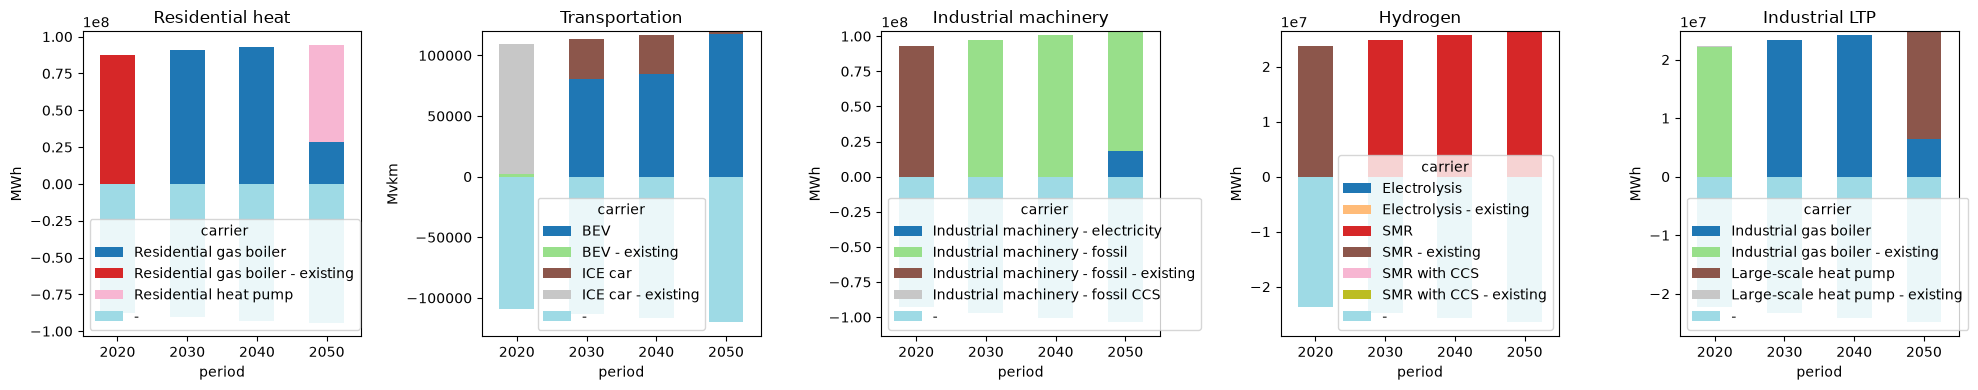

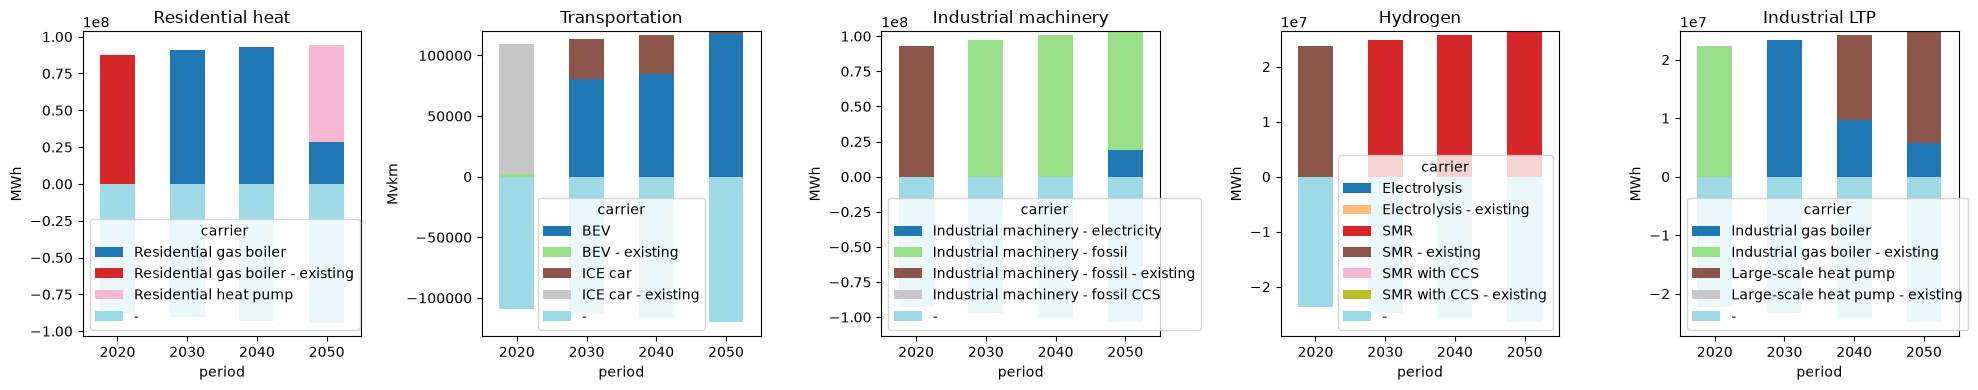

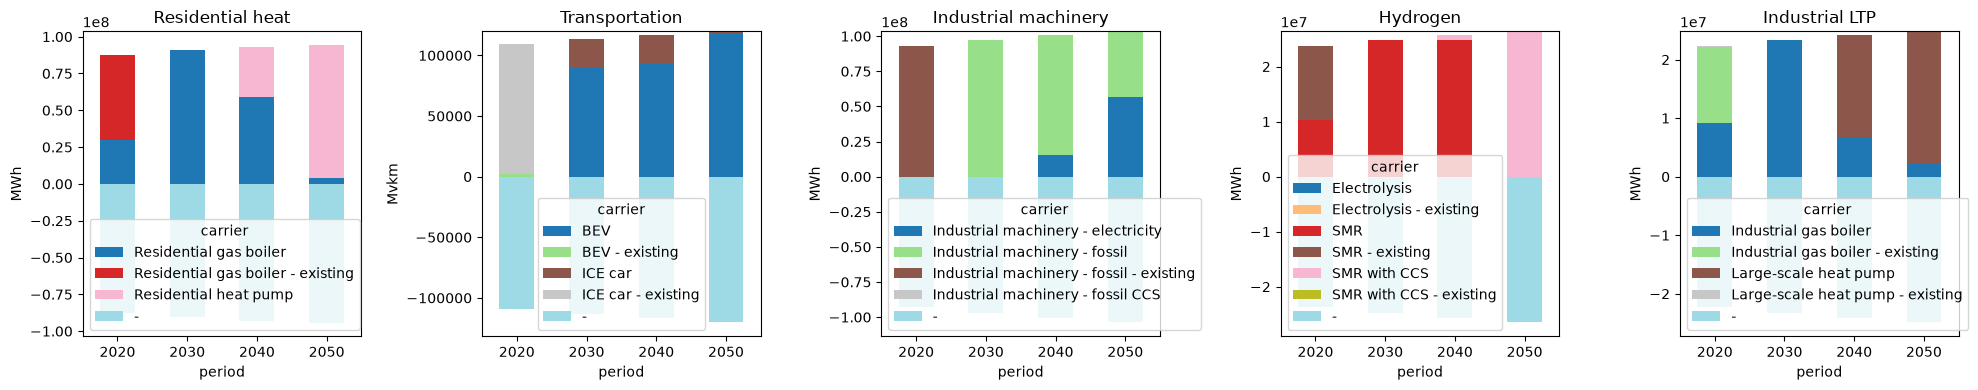

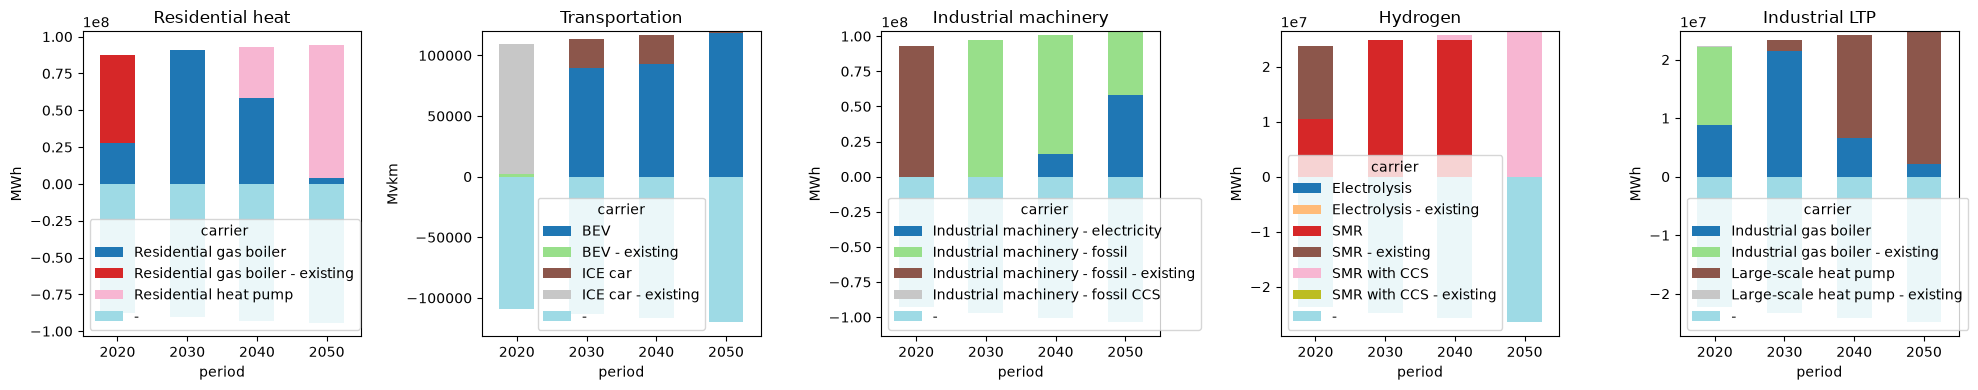

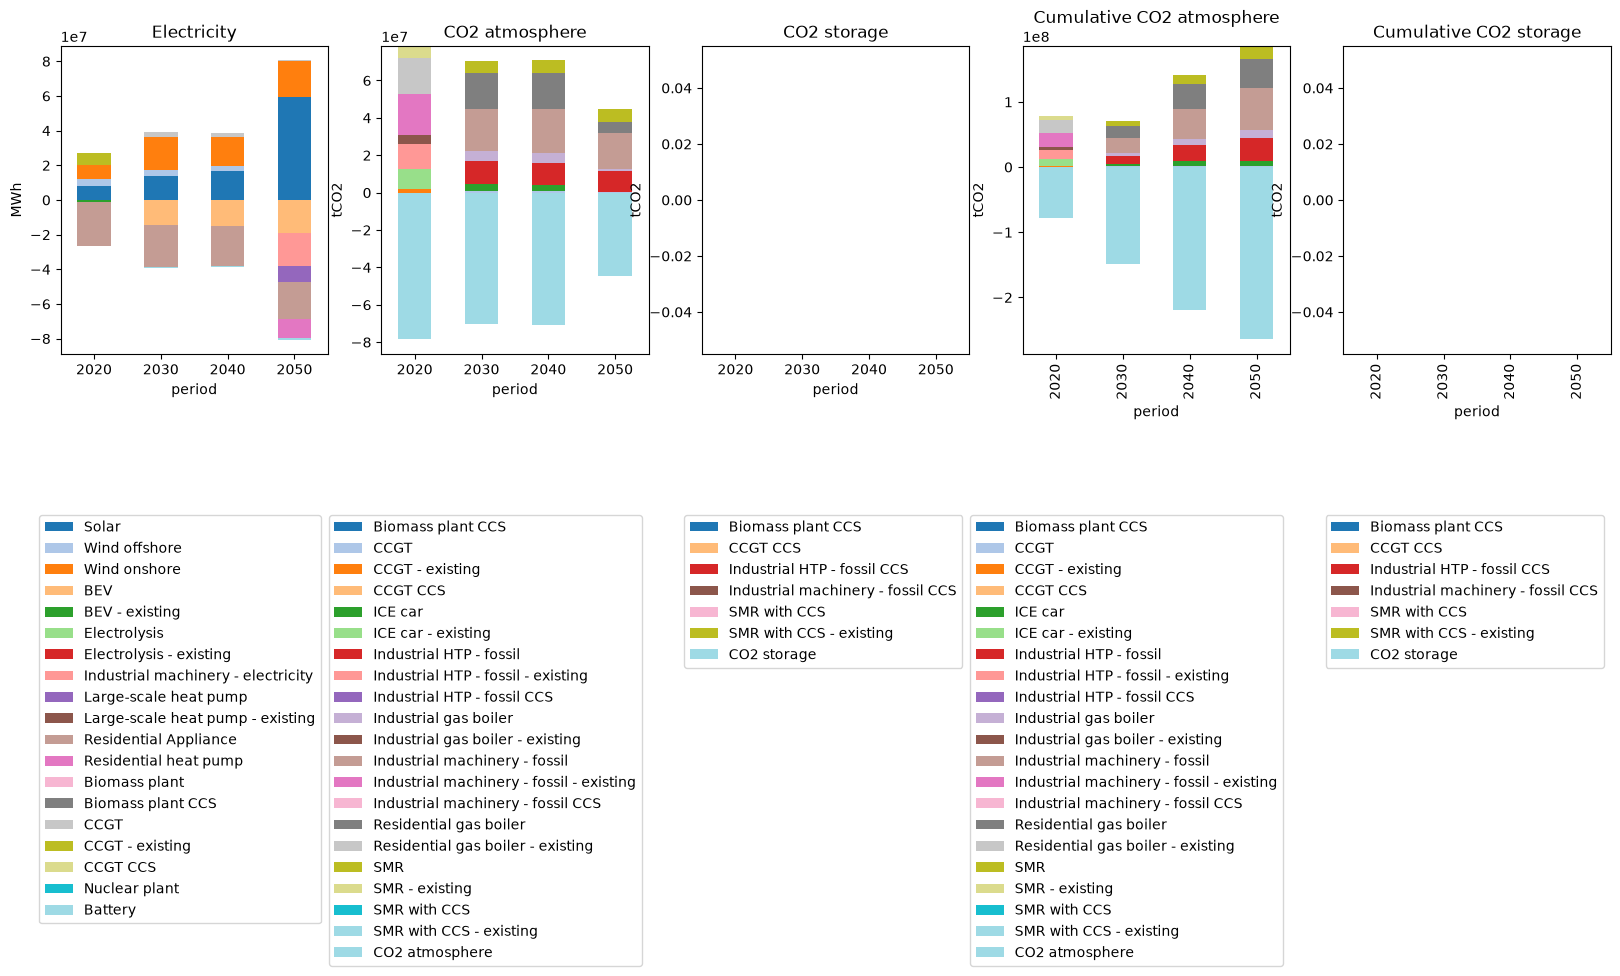

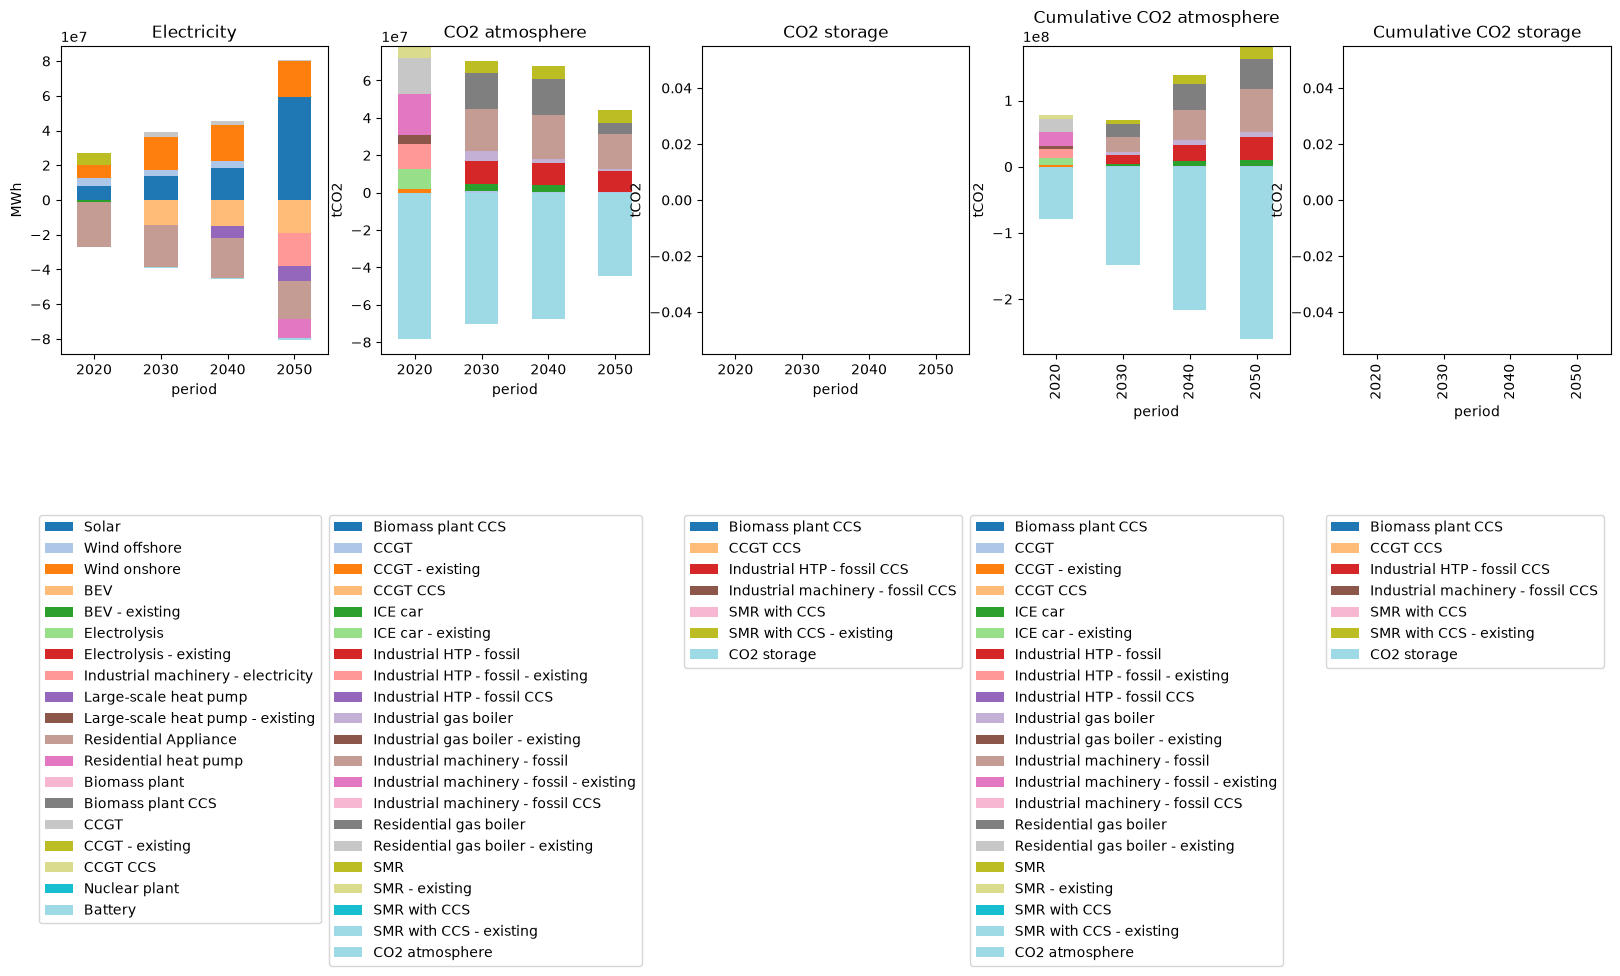

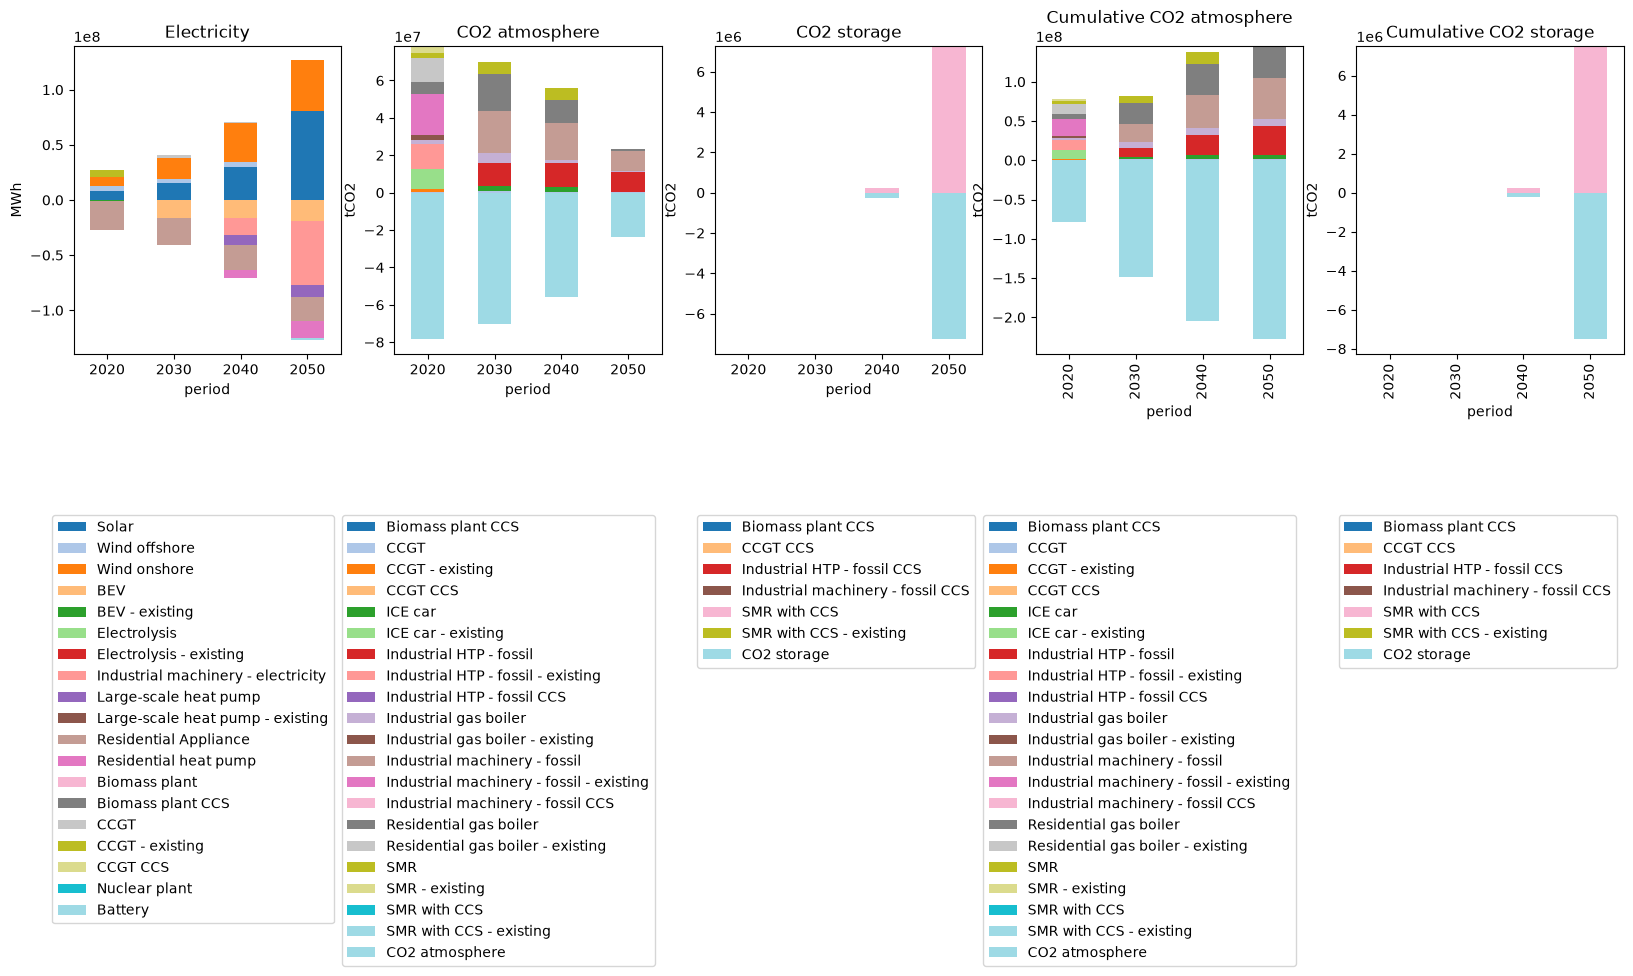

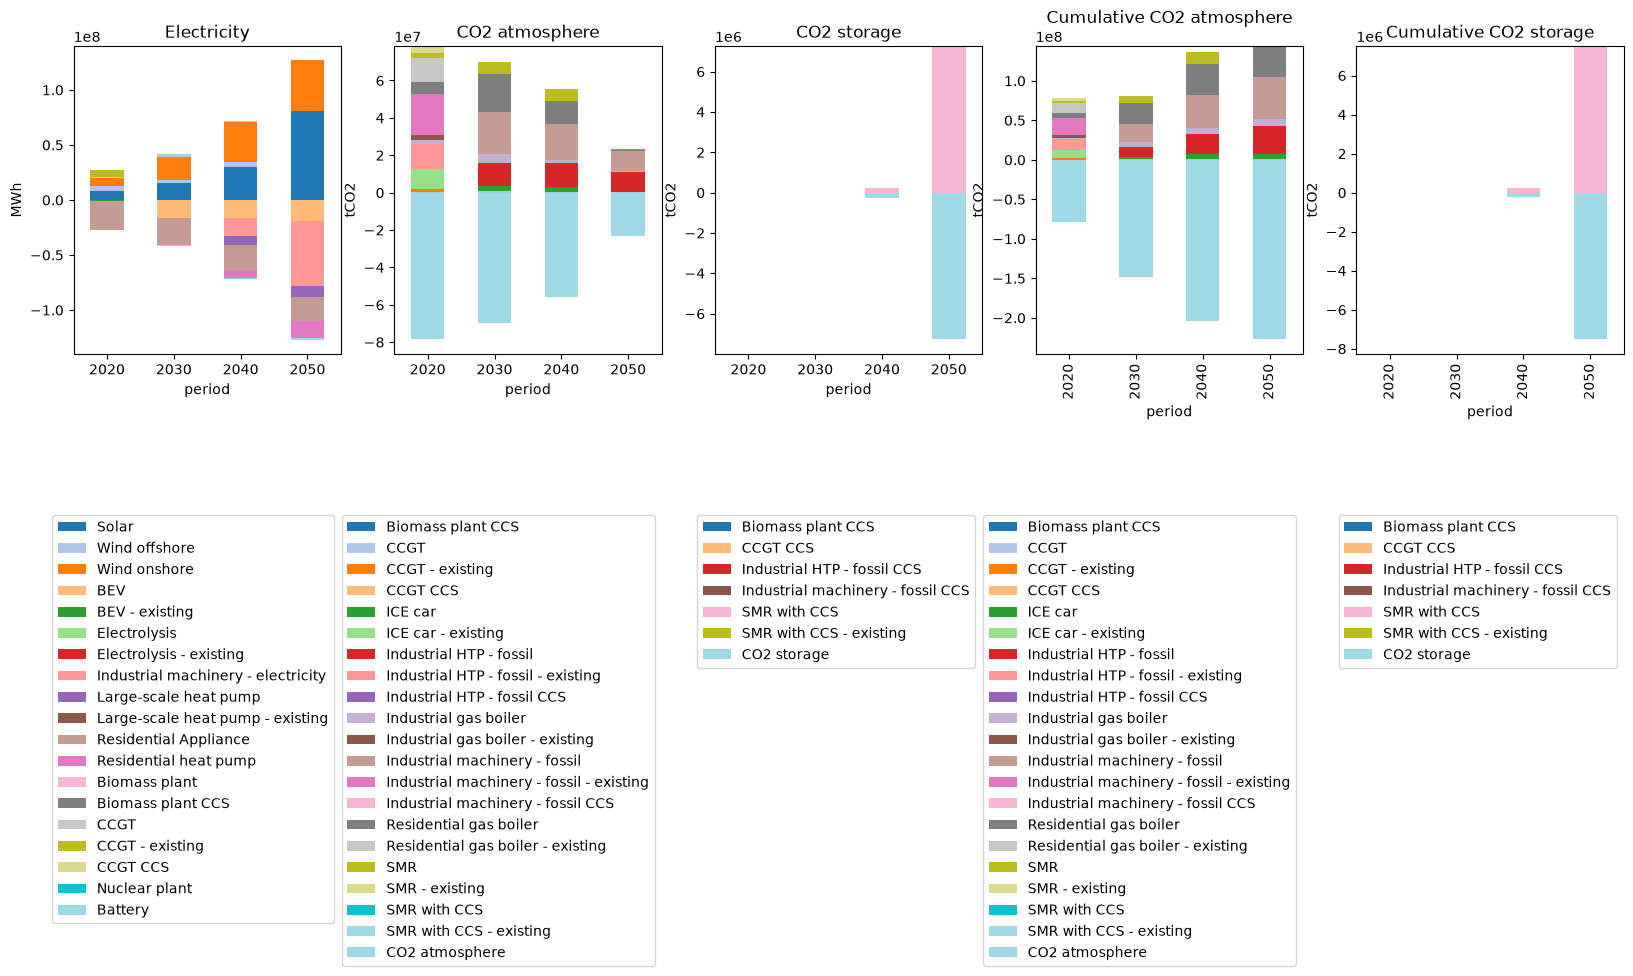

In [33]:
plot_main_ebs_complete(networks['default_tech_low_carbon'])
plot_main_ebs_complete(networks['improved_tech_low_carbon'])
plot_main_ebs_complete(networks['default_tech_high_carbon'])
plot_main_ebs_complete(networks['improved_tech_high_carbon'])

print("default_tech_low_carbon")
plot_elc_emi(networks['default_tech_low_carbon'])
print("improved_tech_low_carbon")
plot_elc_emi(networks['improved_tech_low_carbon'])
print("default_tech_high_carbon")
plot_elc_emi(networks['default_tech_high_carbon'])
print("improved_tech_high_carbon")
plot_elc_emi(networks['improved_tech_high_carbon'])

### 5) Examining industrial low-to-medium heat demand provision

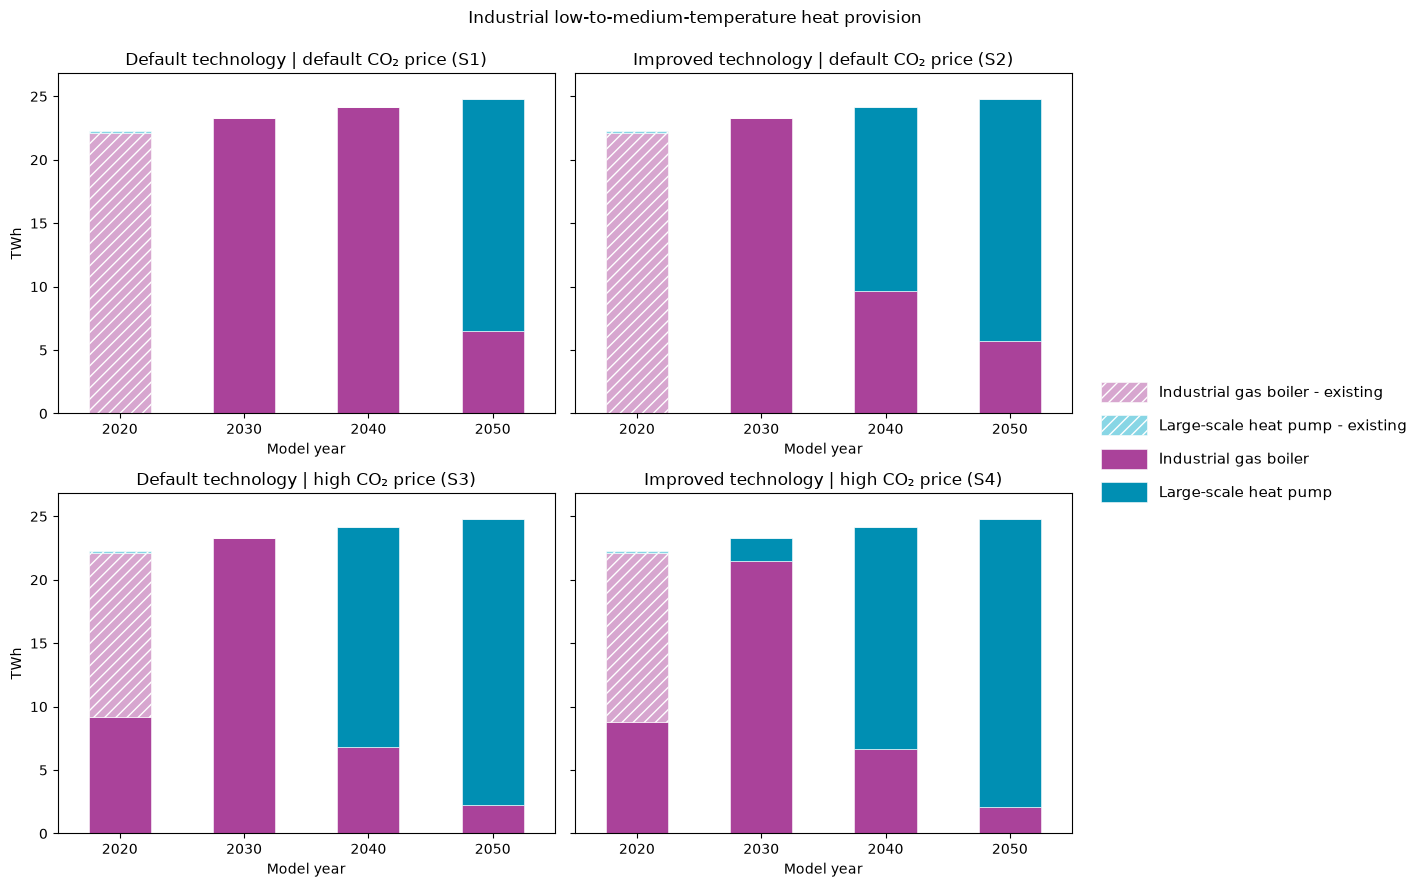

In [15]:
def plot_ltp_heat(networks, scenarios, labels):
    """Extract annual LTP heat supply and plot four stacked-bar panels."""
    if len(scenarios) != 4:
        raise ValueError("Select exactly four scenarios for the 2×2 chart.")

    # Defaults reproduce the gas-boiler and heat-pump colour convention.
    colors = {
        "Industrial gas boiler": "#AA429A",
        "Industrial gas boiler - existing": "#D7A6CF",
        "Large-scale heat pump": "#008FB3",
        "Large-scale heat pump - existing": "#88D6E5",
    }
    tables = {}

    # 1. Extract heat output, weight by represented hours (t_res=7), and sum by year.
    for scenario in scenarios:
        n = networks[scenario]
        heat_buses = n.buses.index[
            n.buses["carrier"].eq("Industrial LTP")
            | n.buses.index.isin(["Industrial LTP"])
        ]
        carriers = n.links["carrier"].astype(str)
        base_carriers = carriers.str.replace(r" - existing$", "", regex=True)
        links = n.links.index[
            n.links["bus1"].isin(heat_buses)
            & base_carriers.isin([
                "Industrial gas boiler", "Large-scale heat pump"
            ])
        ]
        if links.empty:
            raise ValueError(f"No LTP boilers or heat pumps found in {scenario}.")

        # Delivery to bus1 is negative in PyPSA. MW × hours gives MWh.
        heat = (-n.links_t.p1.loc[:, links]).clip(lower=0).mul(
            n.snapshot_weightings["generators"], axis=0
        )
        heat = heat.T.groupby(carriers.loc[links]).sum().T

        if isinstance(n.snapshots, pd.MultiIndex):
            years = n.snapshots.get_level_values(0)
        elif isinstance(n.snapshots, pd.DatetimeIndex):
            years = n.snapshots.year
        else:
            raise ValueError("Expected multi-period or datetime snapshots.")

        tables[scenario] = heat.groupby(years).sum() / 1e6  # MWh → TWh

    # 2. Use the same technologies, year positions, and y-axis in every panel.
    technologies = sorted({
        c for table in tables.values() for c in table.columns
        if table[c].abs().max() > 1e-8
    })
    if not technologies:
        raise ValueError("No nonzero LTP heat supply to plot.")

    years = sorted({year for table in tables.values() for year in table.index})
    max_supply = max(table.sum(axis=1).max() for table in tables.values())
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

    for ax, scenario in zip(axes.flat, scenarios):
        table = tables[scenario].reindex(
            index=years, columns=technologies
        ).fillna(0)
        table.plot.bar(
            stacked=True, ax=ax, rot=0, legend=False,
            color=[colors.get(c, "#B0B5BC") for c in technologies],
            edgecolor="white", linewidth=0.4,
        )
        for technology, container in zip(technologies, ax.containers):
            if technology.endswith(" - existing"):
                for bar in container:
                    bar.set_hatch("///")

        ax.set_title(labels[scenario])
        ax.set_xlabel("Model year")
        ax.set_ylabel("TWh")
        ax.set_ylim(0, max_supply * 1.08)  # added so the 2050 bar does not touch the top
        ax.grid(False)

    # 3. Add one shared legend, with existing technologies listed first.
    legend_order = sorted(
        technologies,
        key=lambda c: (not c.endswith(" - existing"), c.lower()),
    )
    fig.legend(
        handles=[
            Patch(
                facecolor=colors.get(c, "#B0B5BC"), edgecolor="white",
                linewidth=0.4,
                hatch="///" if c.endswith(" - existing") else None,
                label=c,
            )
            for c in legend_order
        ],
        loc="center left", bbox_to_anchor=(0.78, 0.5),
        frameon=False,
        fontsize=11,        
        handlelength=3.0,   
        handleheight=1.6,   
        labelspacing=0.9,   
    )
    fig.tight_layout(rect=[0, 0, 0.78, 0.95])  # was 0.82, leaves room for the larger legend
    fig.suptitle("Industrial low-to-medium-temperature heat provision")
    plt.show()
    return fig, axes


# Reuse the loaded networks and scenario labels; produce the chart.
fig, axes = plot_ltp_heat(networks, SCENARIOS, LABELS)

### 6. Examining emissions

Absolute cumulative direct boiler emissions at final model year (MtCO2):
default_tech_low_carbon      137.156
improved_tech_low_carbon     104.236
default_tech_high_carbon      94.026
improved_tech_high_carbon     89.415

Additional boiler savings from higher carbon pricing (MtCO2):
Default technology     43.130
Improved technology    14.821

Technology-associated boiler savings at fixed carbon price (MtCO2):
Default carbon price    32.920
High carbon price        4.611


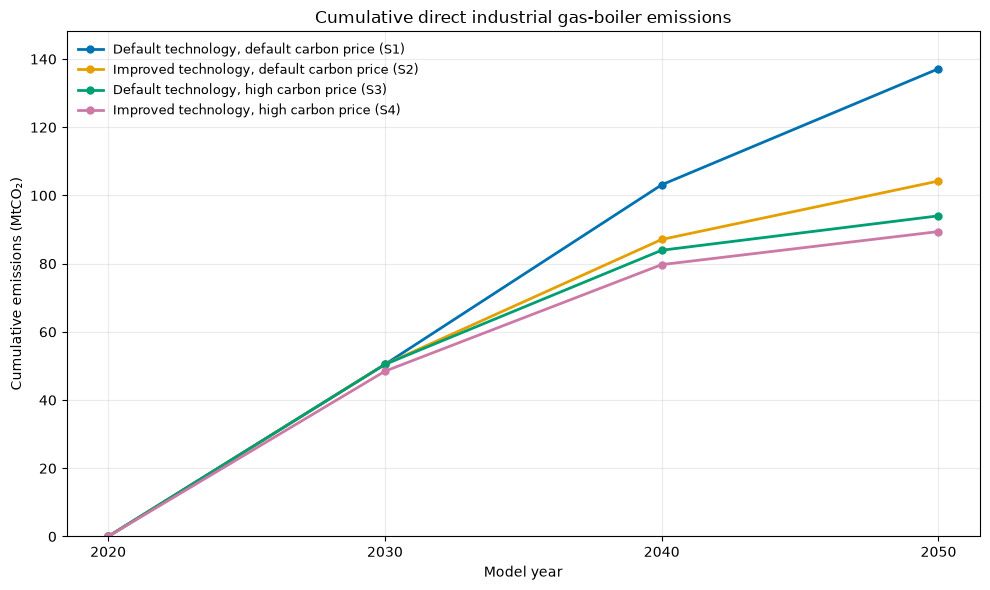

In [16]:
def plot_cumulative_boiler_emissions(networks):
    """Compare direct industrial LTP gas-boiler emissions in four scenarios.

    Requires annual_emissions() and integrate_annual_rates() from the previous
    emissions-contribution code. Uses the same annual weighting and trapezoidal
    integration, with cumulative emissions equal to zero in the first year.
    """
    scenarios = [
        ("default_tech_low_carbon", "Default technology, default carbon price (S1)", "#0072B2", "-"),
        ("improved_tech_low_carbon", "Improved technology, default carbon price (S2)", "#E69F00", "-"),
        ("default_tech_high_carbon", "Default technology, high carbon price (S3)", "#009E73", "-"),
        ("improved_tech_high_carbon", "Improved technology, high carbon price (S4)", "#CC79A7", "-"),
    ]

    annual_series = {}
    cumulative_series = {}
    common_years = None
    for name, label, color, linestyle in scenarios:
        annual = annual_emissions(networks[name])[["Gas boilers"]]
        if common_years is None:
            common_years = annual.index
        elif not annual.index.equals(common_years):
            raise ValueError("All four scenarios must contain the same model years.")
        annual_series[name] = annual["Gas boilers"]
        cumulative_series[name] = integrate_annual_rates(annual)["Gas boilers"]

    annual_results = pd.DataFrame(annual_series)
    cumulative_results = pd.DataFrame(cumulative_series)
    years = common_years.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(10, 6))
    for name, label, color, linestyle in scenarios:
        ax.plot(
            years, cumulative_results[name],
            color=color, linestyle=linestyle, marker="o", linewidth=2,
            markersize=5, label=label,
        )

    ax.set_title("Cumulative direct industrial gas-boiler emissions")
    ax.set_xlabel("Model year")
    ax.set_ylabel("Cumulative emissions (MtCO₂)")
    ax.set_xticks(years)
    minimum = min(0.0, cumulative_results.min().min())
    maximum = max(0.0, cumulative_results.max().max())
    padding = 0.08 * (maximum - minimum) if maximum > minimum else 1.0
    ax.set_ylim(minimum - padding if minimum < 0 else 0, maximum + padding)
    ax.grid(True, alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()

    print("Absolute cumulative direct boiler emissions at final model year (MtCO2):")
    print(cumulative_results.iloc[-1].round(3).to_string())
    print("\nAdditional boiler savings from higher carbon pricing (MtCO2):")
    print(pd.Series({
        "Default technology": (
            cumulative_results["default_tech_low_carbon"].iloc[-1]
            - cumulative_results["default_tech_high_carbon"].iloc[-1]
        ), 
        "Improved technology": (
            cumulative_results["improved_tech_low_carbon"].iloc[-1]
            - cumulative_results["improved_tech_high_carbon"].iloc[-1]
        ),
    }).round(3).to_string())
    print("\nTechnology-associated boiler savings at fixed carbon price (MtCO2):")
    print(pd.Series({
        "Default carbon price": (
            cumulative_results["default_tech_low_carbon"].iloc[-1]
            - cumulative_results["improved_tech_low_carbon"].iloc[-1]
        ),
        "High carbon price": (
            cumulative_results["default_tech_high_carbon"].iloc[-1]
            - cumulative_results["improved_tech_high_carbon"].iloc[-1]
        ),
    }).round(3).to_string())

    plt.show()
    return fig, ax, annual_results, cumulative_results


# Run the earlier emissions-contribution cell first to define
# annual_emissions() and integrate_annual_rates().
fig_boilers, ax_boilers, annual_boiler_emissions, cumulative_boiler_emissions = (
    plot_cumulative_boiler_emissions(networks)
)

Absolute cumulative emissions, 2020–2050 (MtCO2):
      System  Gas boilers
S1  2027.423      137.156
S2  1993.886      104.236
S3  1771.015       94.026
S4  1762.990       89.415

Reductions relative to S1 (technology, pricing, both):
    Total reduction  Direct boiler reduction  Remaining net reduction  Boiler share of total reduction (%)  Baseline emissions avoided (%)
S3          256.408                   43.130                  213.278                               16.821                          12.647
S2           33.537                   32.920                    0.617                               98.160                           1.654
S4          264.433                   47.741                  216.692                               18.054                          13.043


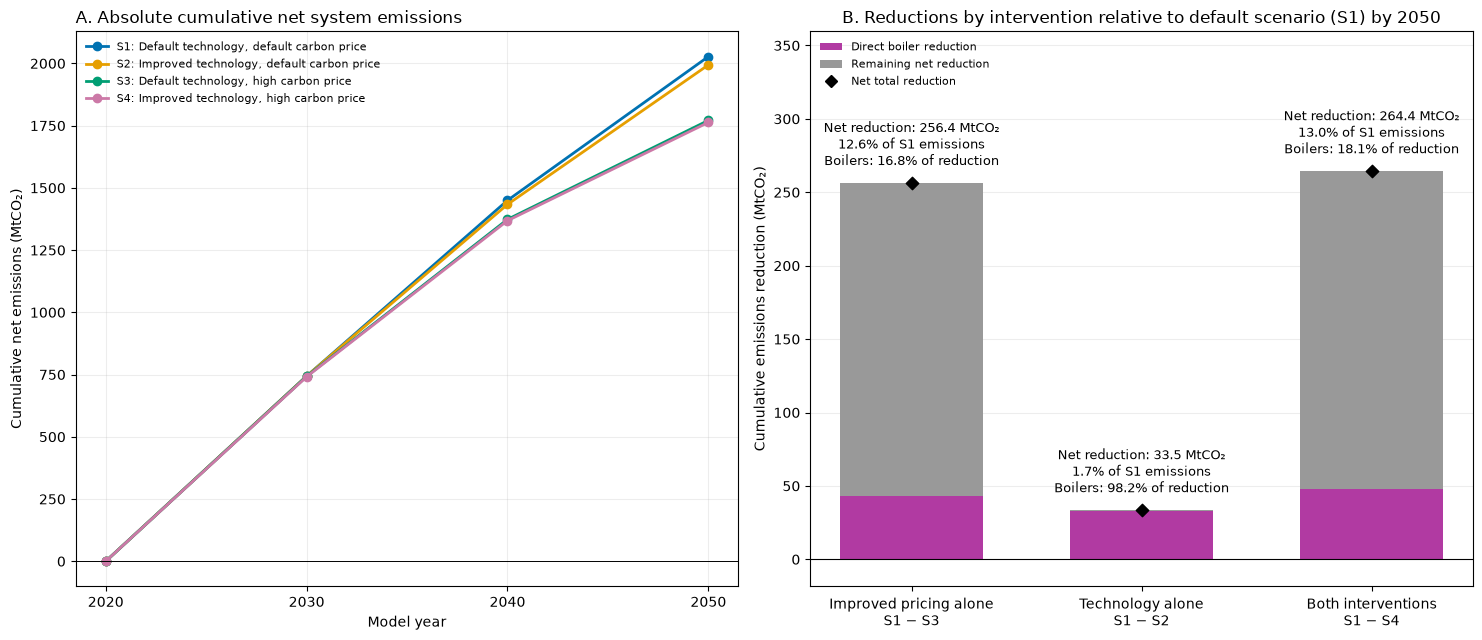

In [48]:
def plot_system_intervention_effects(
    annual_by_scenario,
    system_column="System",
    boiler_column="Gas boilers",
    start_year=None,
    end_year=None,
    save_prefix=None,
):
    """Plot cumulative system emissions and reductions relative to S1.

    Scenario mapping:
      S1: default technology, default carbon price
      S2: improved technology, default carbon price
      S3: default technology, high carbon price
      S4: improved technology, high carbon price

    Input: dictionary of annual-emissions DataFrames indexed by model year.
    Cumulative emissions start at zero in the first selected model year.
    """
    styles = {
        "S1": ("Default technology, default carbon price", "#0072B2", "-"),
        "S2": ("Improved technology, default carbon price", "#E69F00", "-"),
        "S3": ("Default technology, high carbon price", "#009E73", "-"),
        "S4": ("Improved technology, high carbon price", "#CC79A7", "-"),
    }
    annual = {}
    common_years = None
    for scenario in styles:
        if scenario not in annual_by_scenario:
            raise KeyError(f"Missing scenario {scenario}.")
        source = annual_by_scenario[scenario].copy()
        missing = [c for c in (system_column, boiler_column) if c not in source.columns]
        if missing:
            raise ValueError(
                f"{scenario}: missing columns {missing}. Available columns: "
                f"{list(source.columns)}. Set system_column and boiler_column "
                "to the appropriate annual-emissions column names."
            )
        table = source[[system_column, boiler_column]].astype(float)
        table.index = pd.Index(pd.to_numeric(table.index), name="Model year")
        table = table.sort_index()
        if table.index.has_duplicates:
            raise ValueError(f"{scenario}: duplicate model years.")
        if start_year is not None:
            if start_year not in table.index:
                raise ValueError(f"{scenario}: start_year must be a model year.")
            table = table.loc[table.index >= start_year]
        if end_year is not None:
            if end_year not in table.index:
                raise ValueError(f"{scenario}: end_year must be a model year.")
            table = table.loc[table.index <= end_year]
        if len(table) < 2 or not np.isfinite(table.to_numpy()).all():
            raise ValueError(f"{scenario}: need at least two years and finite rates.")
        if common_years is None:
            common_years = table.index
        elif not table.index.equals(common_years):
            raise ValueError("All scenarios must have identical model years.")
        annual[scenario] = table

    years = common_years.to_numpy(dtype=float)
    cumulative = {}
    for scenario, table in annual.items():
        rates = table.to_numpy()
        increments = (rates[:-1] + rates[1:]) * 0.5 * np.diff(years)[:, None]
        integrated = np.vstack([np.zeros((1, 2)), np.cumsum(increments, axis=0)])
        cumulative[scenario] = pd.DataFrame(
            integrated, index=common_years, columns=[system_column, boiler_column]
        )

    final = pd.DataFrame({s: t.iloc[-1] for s, t in cumulative.items()}).T
    baseline = final.loc["S1", system_column]
    # Order the bars as technology alone, pricing alone, both together.
    effects = pd.DataFrame(index=["S3", "S2", "S4"])
    effects["Total reduction"] = baseline - final.loc[effects.index, system_column]
    effects["Direct boiler reduction"] = (
        final.loc["S1", boiler_column] - final.loc[effects.index, boiler_column]
    )
    effects["Remaining net reduction"] = (
        effects["Total reduction"] - effects["Direct boiler reduction"]
    )
    # Percent contribution of direct boiler reductions to the total reduction.
    # NaN where the total is zero, since the share is undefined there.
    # Can fall outside 0-100% if the total is small or the remaining part is negative.
    effects["Boiler share of total reduction (%)"] = np.where(
        effects["Total reduction"] != 0,
        100 * effects["Direct boiler reduction"] / effects["Total reduction"],
        np.nan,
    )
    effects["Baseline emissions avoided (%)"] = (
        100 * effects["Total reduction"] / baseline if baseline > 0 else np.nan
    )
    interaction = (
        effects.loc["S4", "Total reduction"]
        - effects.loc["S3", "Total reduction"]
        - effects.loc["S2", "Total reduction"]
    )

    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15, 6.5))
    for scenario, (label, color, linestyle) in styles.items():
        ax_a.plot(
            years, cumulative[scenario][system_column], color=color,
            linestyle=linestyle, marker="o", linewidth=2,
            label=f"{scenario}: {label}",
        )
    ax_a.set_title("A. Absolute cumulative net system emissions", loc="left")
    ax_a.set_xlabel("Model year")
    ax_a.set_ylabel("Cumulative net emissions (MtCO₂)")
    ax_a.set_xticks(years)
    ax_a.axhline(0, color="black", linewidth=0.7)
    ax_a.grid(True, alpha=0.22)
    ax_a.set_axisbelow(True)
    ax_a.legend(frameon=False, fontsize=8, loc="best")

    x = np.arange(3)
    components = [
        ("Direct boiler reduction", "#B13AA2"),
        ("Remaining net reduction", "#999999"),
    ]
    positive_bottom = np.zeros(3)
    negative_bottom = np.zeros(3)
    for column, color in components:
        values = effects[column].to_numpy(dtype=float)
        bottoms = np.where(values >= 0, positive_bottom, negative_bottom)
        ax_b.bar(x, values, bottom=bottoms, width=0.62, color=color)
        positive_bottom += np.maximum(values, 0)
        negative_bottom += np.minimum(values, 0)

    totals = effects["Total reduction"].to_numpy(dtype=float)
    ax_b.scatter(x, totals, marker="D", s=40, color="black", zorder=4)
    span = max(float(positive_bottom.max() - negative_bottom.min()), 1.0)
    for i, scenario in enumerate(effects.index):
        pct = effects.loc[scenario, "Baseline emissions avoided (%)"]
        share = effects.loc[scenario, "Boiler share of total reduction (%)"]
        label = f"Net reduction: {totals[i]:.1f} MtCO₂"
        if np.isfinite(pct):
            label += f"\n{pct:.1f}% of S1 emissions"
        if np.isfinite(share):
            label += f"\nBoilers: {share:.1f}% of reduction"
        ax_b.text(x[i], positive_bottom[i] + 0.035 * span, label,
                  ha="center", va="bottom", fontsize=9)
    ax_b.set_ylim(negative_bottom.min() - 0.07 * span,
                  positive_bottom.max() + 0.36 * span)
    ax_b.set_xticks(x)
    ax_b.set_xticklabels([
        "Improved pricing alone\nS1 − S3",
        "Technology alone\nS1 − S2",
        "Both interventions\nS1 − S4",
    ])
    ax_b.set_title("B. Reductions by intervention relative to default scenario (S1) by 2050")
    ax_b.set_ylabel("Cumulative emissions reduction (MtCO₂)")
    ax_b.axhline(0, color="black", linewidth=0.8)
    ax_b.grid(axis="y", alpha=0.22)
    ax_b.set_axisbelow(True)
    handles = [Patch(facecolor=color, label=name) for name, color in components]
    handles.append(plt.Line2D([0], [0], color="black", marker="D",
                              linestyle="None", label="Net total reduction"))
    ax_b.legend(handles=handles, frameon=False, fontsize=8, loc="upper left")

    fig.tight_layout()
    if save_prefix:
        fig.savefig(f"{save_prefix}.png", dpi=300, bbox_inches="tight")
        fig.savefig(f"{save_prefix}.pdf", bbox_inches="tight")
        effects.to_csv(f"{save_prefix}_reductions.csv")
        final.to_csv(f"{save_prefix}_absolute_emissions.csv")

    print(f"Absolute cumulative emissions, {years[0]:g}–{years[-1]:g} (MtCO2):")
    print(final.round(3).to_string())
    print("\nReductions relative to S1 (technology, pricing, both):")
    print(effects.round(3).to_string())

    plt.show()
    return fig, (ax_a, ax_b), cumulative, effects, final


# Run your earlier extraction cell first to define annual_emissions().
# The underlying network keys are unchanged; only scenario numbering changes.
annual_by_scenario = {
    "S1": annual_emissions(networks["default_tech_low_carbon"]),
    "S2": annual_emissions(networks["improved_tech_low_carbon"]),
    "S3": annual_emissions(networks["default_tech_high_carbon"]),
    "S4": annual_emissions(networks["improved_tech_high_carbon"]),
}

fig_system, axes_system, cumulative_system, intervention_effects, final_emissions = (
    plot_system_intervention_effects(
        annual_by_scenario,
        system_column="System",  # Set to the actual NET system-emissions column name.
        boiler_column="Gas boilers",
        save_prefix=None,  # Set a filename prefix to export PNG, PDF and CSVs.
    )
)

### 7. Examining electricity demand and supply

Annual electricity demand at final model year (TWh/year):
Default technology | default CO₂ price (S1)      79.643
Improved technology | default CO₂ price (S2)     79.449
Default technology | high CO₂ price (S3)        125.044
Improved technology | high CO₂ price (S4)       125.256

Supply CSV saved: results/visualisations/electricity_supply_mix_by_year.csv
Demand CSV saved: results/visualisations/electricity_demand_by_year.csv
Combined figure saved: results/visualisations/electricity_demand_and_supply_by_year.png


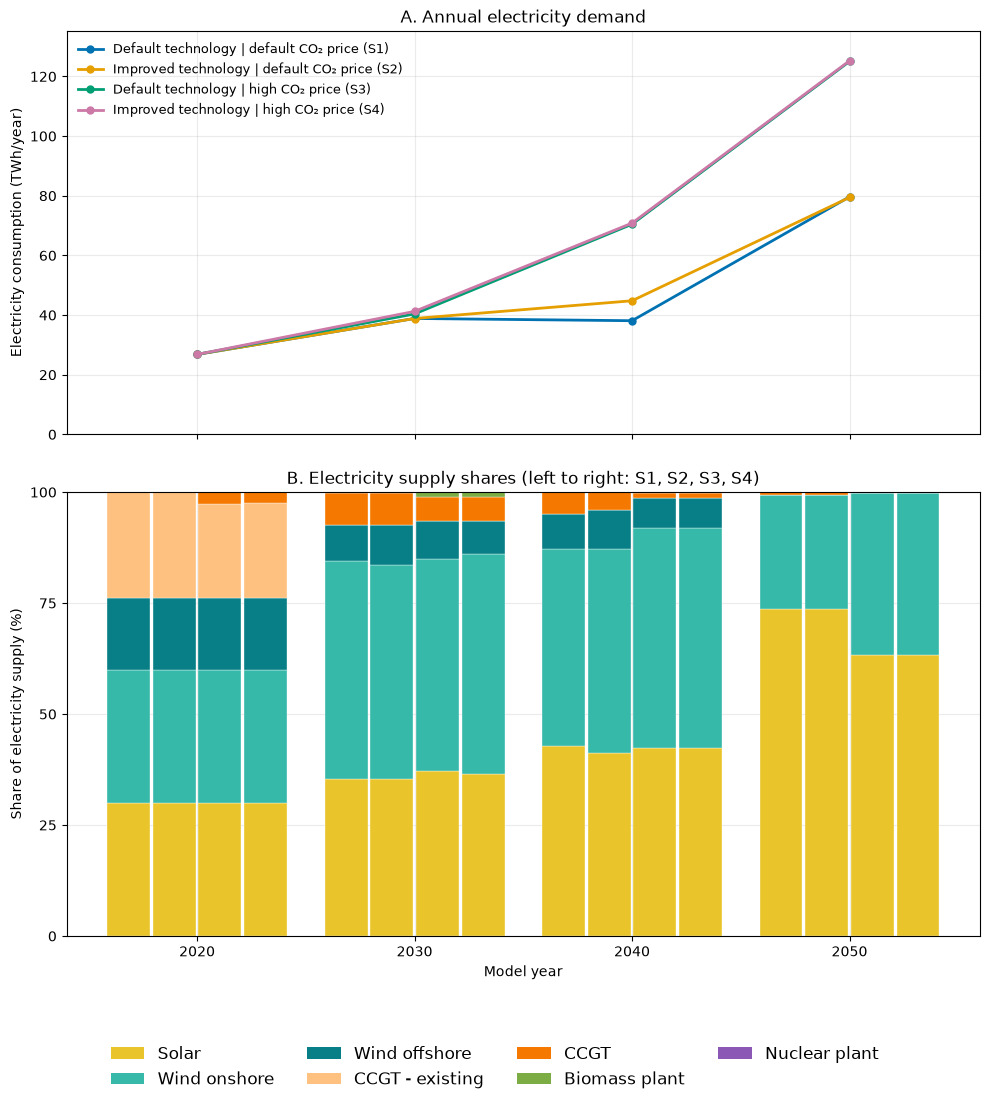

In [18]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch


# Uses the notebook's existing SCENARIOS, LABELS, networks and tech_colors.
# No networks are reloaded and SCENARIOS / LABELS are not redefined.


def _electricity_year_groups(n, years_to_plot=None):
    """Return snapshots grouped by model year.

    For MultiIndex snapshots, the first level must contain model years.
    """
    if isinstance(n.snapshots, pd.MultiIndex):
        raw_years = n.snapshots.get_level_values(0)
    elif isinstance(n.snapshots, pd.DatetimeIndex):
        raw_years = n.snapshots.year
    else:
        raise ValueError("Snapshots must be a MultiIndex or DatetimeIndex.")

    year_values = np.asarray(raw_years, dtype=int)
    selected = None if years_to_plot is None else {int(y) for y in years_to_plot}
    groups = [
        (int(year), n.snapshots[year_values == year])
        for year in sorted(pd.unique(year_values))
        if selected is None or int(year) in selected
    ]
    if not groups:
        raise ValueError("No snapshots match years_to_plot.")
    return groups


def plot_electricity_demand_and_supply(
    networks,
    tech_colors,
    years_to_plot=None,
    electricity_bus="Electricity",
    exclude_link_carriers=None,
    technology_labels=None,
    scenario_styles=None,
    output_dir="results/visualisations",
    show=True,
):
    """Compare annual electricity demand and supply shares in two panels.

    Defaults to the notebook's SCENARIOS order and LABELS. Scenario colours
    match plot_cumulative_boiler_emissions; all default lines are solid.
    All selected networks must contain the same selected model years.

    Top: annual electricity withdrawals by Links connected at bus0.
    Bottom: grouped stacked supply-share bars in SCENARIOS order, coloured
    exclusively from tech_colors. Each year's bars run S1 to S4 left to right
    when using the notebook's four-scenario order.

    Supply includes positive Generator dispatch and positive injections at
    Link output ports. StorageUnits and Stores are excluded. Discharge Links
    remain included unless their carriers are in exclude_link_carriers.
    Demand excludes Loads and withdrawals at other Link ports.

    Snapshot generator weights must represent hours within each modeled year.
    No cumulative integration or investment-period weighting is applied.

    tech_colors may use displayed technology labels or original carrier names.
    For differently coloured carriers merged into one technology label, supply
    an explicit tech_colors entry for that displayed label.

    Returns fig, axes (shape (2,)), supply_df and demand_df.
    """
    scenario_colors = {
        "default_tech_low_carbon": "#0072B2",
        "improved_tech_low_carbon": "#E69F00",
        "default_tech_high_carbon": "#009E73",
        "improved_tech_high_carbon": "#CC79A7",
    }
    if scenario_styles is None:
        # Read the existing notebook objects when the function is called.
        styles = [(name, LABELS[name], scenario_colors[name], "-")
                  for name in SCENARIOS]
    else:
        styles = list(scenario_styles)

    scenario_order = [name for name, label, color, linestyle in styles]
    if not scenario_order or len(scenario_order) != len(set(scenario_order)):
        raise ValueError("Scenario keys must be nonempty and unique.")
    missing = [name for name in scenario_order if name not in networks]
    if missing:
        raise ValueError(f"Missing loaded networks: {missing}")

    excluded = set() if exclude_link_carriers is None else set(exclude_link_carriers)
    technology_labels = {} if technology_labels is None else technology_labels
    label_carriers = {}
    records = []
    annual_series = {}
    common_years = None

    def technology_label(row, name):
        carrier = row.get("carrier", "")
        if pd.isna(carrier) or not str(carrier).strip():
            carrier = re.sub(r"_\d{4}$", "", str(name))
        carrier = str(carrier)
        label = technology_labels.get(carrier, carrier)
        label_carriers.setdefault(label, set()).add(carrier)
        return label

    for name in scenario_order:
        n = networks[name]
        if electricity_bus not in n.buses.index:
            raise ValueError(f"{name}: no {electricity_bus!r} bus.")
        groups = _electricity_year_groups(n, years_to_plot)
        model_years = pd.Index([year for year, _ in groups], name="Year")
        if common_years is None:
            common_years = model_years
        elif not model_years.equals(common_years):
            raise ValueError("All scenarios must contain the same selected model years.")

        weights_all = n.snapshot_weightings["generators"]
        generator_names = n.generators.index[
            n.generators["bus"].eq(electricity_bus)
        ]
        sources = [
            (technology_label(n.generators.loc[g], g), n.generators_t.p[g])
            for g in generator_names
        ]
        output_ports = sorted(
            [c for c in n.links.columns if re.fullmatch(r"bus[1-9]\d*", str(c))],
            key=lambda c: int(c[3:]),
        )
        carriers = n.links.get("carrier", pd.Series("", index=n.links.index))
        for port in output_ports:
            link_names = n.links.index[
                n.links[port].eq(electricity_bus) & ~carriers.isin(excluded)
            ]
            if len(link_names):
                flows = n.links_t["p" + port[3:]]
                sources.extend(
                    (technology_label(n.links.loc[link], link), -flows[link])
                    for link in link_names
                )

        demand_links = n.links.index[n.links["bus0"].eq(electricity_bus)]
        if not len(demand_links):
            warnings.warn(f"{name}: no electricity-consuming Links at bus0.")
        annual_demand = {}
        for year, snapshots in groups:
            weights = weights_all.loc[snapshots]
            if len(demand_links):
                use = n.links_t.p0.loc[snapshots, demand_links].clip(lower=0)
                annual_demand[year] = float(use.mul(weights, axis=0).sum().sum()) / 1e6
            else:
                annual_demand[year] = 0.0

            production = {}
            for technology, output in sources:
                mwh = float(output.loc[snapshots].clip(lower=0).mul(weights).sum())
                production[technology] = production.get(technology, 0.0) + mwh
            total_mwh = sum(production.values())
            if total_mwh <= 0:
                warnings.warn(f"No positive electricity supply: {name}, {year}")
            for technology, mwh in production.items():
                records.append({
                    "Scenario": name,
                    "Year": year,
                    "Technology": technology,
                    "Electricity_MWh": mwh,
                    "Electricity_TWh": mwh / 1e6,
                    "Share_Pct": 100 * mwh / total_mwh if total_mwh > 0 else np.nan,
                    "Total_Electricity_TWh": total_mwh / 1e6,
                })
        annual_series[name] = pd.Series(annual_demand, dtype=float)

    if not records:
        raise ValueError("No electricity supply sources found.")
    supply_df = pd.DataFrame(records).sort_values(["Scenario", "Year", "Technology"])
    demand_df = pd.DataFrame(annual_series).reindex(
        index=common_years, columns=scenario_order
    )
    positive_supply = supply_df.loc[supply_df["Total_Electricity_TWh"] > 0]
    if positive_supply.empty:
        raise ValueError("All scenario-year groups have zero electricity supply.")
    totals = positive_supply.groupby("Technology")["Electricity_MWh"].sum()
    technologies = totals[totals > 0].sort_values(ascending=False).index.tolist()

    colors = {}
    for technology in technologies:
        if technology in tech_colors:
            colors[technology] = tech_colors[technology]
            continue
        original_carriers = label_carriers[technology]
        missing_colors = sorted(c for c in original_carriers if c not in tech_colors)
        if missing_colors:
            raise ValueError(
                f"Add tech_colors[{technology!r}] or colours for {missing_colors}."
            )
        carrier_colors = {to_rgba(tech_colors[c]) for c in original_carriers}
        if len(carrier_colors) != 1:
            raise ValueError(
                f"Carriers grouped as {technology!r} have different colours. "
                "Add a tech_colors entry for this displayed label."
            )
        colors[technology] = next(iter(carrier_colors))

    # Use numeric years, as in the boiler-emissions plot.
    years = common_years.to_numpy(dtype=float)
    year_spacing = float(np.diff(years).min()) if len(years) > 1 else 1.0
    group_width = 0.84 * year_spacing
    bar_width = group_width / len(scenario_order)
    legend_cols = min(4, len(technologies))
    legend_rows = (len(technologies) + legend_cols - 1) // legend_cols
    legend_height = 0.4 * legend_rows + 0.4

    fig, axes = plt.subplots(
        2, 1, sharex=True, figsize=(10, 10 + legend_height),
        gridspec_kw={"height_ratios": [1, 1.1]},
    )
    ax_demand, ax_supply = axes
    for name, label, color, linestyle in styles:
        ax_demand.plot(
            years, demand_df[name], color=color, linestyle=linestyle,
            marker="o", linewidth=2, markersize=5, label=label,
        )
    ax_demand.set_title("A. Annual electricity demand")
    ax_demand.set_ylabel("Electricity consumption (TWh/year)")
    maximum = max(0.0, demand_df.max().max())
    padding = 0.08 * maximum if maximum > 0 else 1.0
    ax_demand.set_ylim(0, maximum + padding)
    ax_demand.legend(frameon=False, fontsize=9)

    for i, name in enumerate(scenario_order):
        subset = positive_supply.loc[positive_supply["Scenario"].eq(name)]
        if subset.empty:
            continue
        shares = subset.pivot(
            index="Year", columns="Technology", values="Share_Pct"
        ).reindex(columns=technologies).fillna(0).reindex(index=common_years)
        positions = years + (i - (len(scenario_order) - 1) / 2) * bar_width
        bottom = np.zeros(len(years))
        for technology in technologies:
            values = shares[technology].to_numpy()
            ax_supply.bar(
                positions, values, bottom=bottom, width=bar_width * 0.94,
                color=colors[technology], edgecolor="white", linewidth=0.25,
            )
            bottom += np.nan_to_num(values, nan=0.0)

    # Order matches the demand legend and the notebook's SCENARIOS object.
    bar_order = ", ".join(f"S{i + 1}" for i in range(len(scenario_order)))
    ax_supply.set_title(f"B. Electricity supply shares (left to right: {bar_order})")
    ax_supply.set_ylabel("Share of electricity supply (%)")
    ax_supply.set_xlabel("Model year")
    ax_supply.set_ylim(0, 100)
    ax_supply.set_yticks([0, 25, 50, 75, 100])
    ax_supply.set_xlim(years[0] - 0.6 * year_spacing, years[-1] + 0.6 * year_spacing)
    for ax in axes:
        ax.set_xticks(years)
        ax.grid(True, alpha=0.25)
        ax.set_axisbelow(True)

    handles = [Patch(facecolor=colors[t], label=t) for t in technologies]
    fig.legend(
        handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.01),
        ncol=legend_cols, frameon=False, fontsize=12,
    )
    fig.tight_layout(rect=[0, legend_height / fig.get_figheight(), 1, 1], h_pad=2)

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    supply_path = output_dir / "electricity_supply_mix_by_year.csv"
    demand_path = output_dir / "electricity_demand_by_year.csv"
    figure_path = output_dir / "electricity_demand_and_supply_by_year.png"
    supply_df.to_csv(supply_path, index=False)
    demand_df.to_csv(demand_path)
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")

    print("Annual electricity demand at final model year (TWh/year):")
    print(demand_df.iloc[-1].rename(index=dict((s[0], s[1]) for s in styles))
          .round(3).to_string())
    print(f"\nSupply CSV saved: {supply_path}")
    print(f"Demand CSV saved: {demand_path}")
    print(f"Combined figure saved: {figure_path}")
    if show:
        plt.show()
    return fig, axes, supply_df, demand_df



fig, axes, supply_df, demand_df = plot_electricity_demand_and_supply(
     networks, tech_colors=tech_colors,
 )


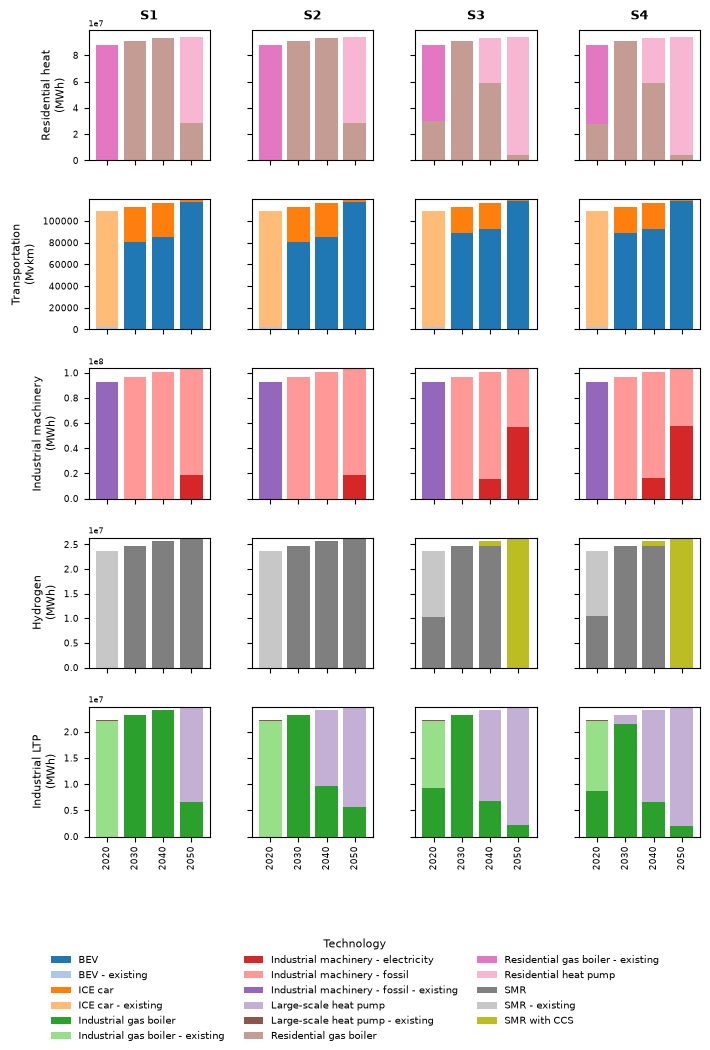

In [43]:
CARRIERS = ['Residential heat', 'Transportation', 'Industrial machinery',
            'Hydrogen', 'Industrial LTP']
UNITS = {'Transportation': 'Mvkm'}          # everything else is MWh


def get_supply(n, carrier):
    """Positive part of the energy balance, summed per carrier (rows = years)."""
    try:
        eb = n.statistics.energy_balance(bus_carrier=carrier)
    except Exception:
        return None
    if isinstance(eb, pd.Series):
        eb = eb.to_frame("total")
    if eb.empty:
        return None
    supply = eb.clip(lower=0).groupby(level=1).sum().T     # years x technologies
    supply.index = supply.index.map(str)
    supply = supply.loc[:, (supply != 0).any()]
    return supply if not supply.empty else None


# ---------- main plot ----------
def plot_main_ebs_complete(networks, scenarios=SCENARIOS, labels=LABELS,
                           carriers=CARRIERS, figsize=(7.2, 10.5), legend_cols=3):
    data = {(s, c): get_supply(networks[s], c) for s in scenarios for c in carriers}

    techs = sorted({t for df in data.values() if df is not None for t in df.columns})
    cmap = plt.get_cmap("tab20")
    colors = {t: cmap(i % 20) for i, t in enumerate(techs)}

    short = {}
    for s in scenarios:
        m = re.search(r"\((S\d)\)", labels[s])
        short[s] = m.group(1) if m else s

    nrows, ncols = len(carriers), len(scenarios)
    fig, ax = plt.subplots(nrows, ncols, figsize=figsize,
                           sharey='row', squeeze=False)

    for i, c in enumerate(carriers):
        for j, s in enumerate(scenarios):
            a = ax[i, j]
            df = data[(s, c)]
            if df is None:
                a.text(0.5, 0.5, "no data", ha='center', va='center',
                       fontsize=7, transform=a.transAxes)
                a.set_xticks([]); a.set_yticks([])
            else:
                df = df[[t for t in techs if t in df.columns]]
                df.plot(kind='bar', stacked=True, ax=a, legend=False, width=0.8,
                        color=[colors[t] for t in df.columns])
                a.set_ylim(bottom=0)

            a.tick_params(axis='both', labelsize=6.5)
            a.tick_params(axis='x', rotation=90)
            a.yaxis.get_offset_text().set_fontsize(6)
            if i < nrows - 1:
                a.set_xticklabels([])
            a.set_xlabel("")

            # column titles (S1-S4) on the top row
            if i == 0:
                a.set_title(short[s], fontsize=9, fontweight="bold", pad=8)

            # row labels (carrier + unit) on the first column
            if j == 0:
                a.set_ylabel(f"{c}\n({UNITS.get(c, 'MWh')})", fontsize=8)
            else:
                a.set_ylabel("")

    # single legend below the plots
    handles = [Patch(facecolor=colors[t], label=t) for t in techs]
    leg_rows = math.ceil(len(handles) / legend_cols)
    legend_h = 0.022 * leg_rows + 0.02
    fig.legend(handles=handles, loc='lower center', ncol=legend_cols, fontsize=7,
               title="Technology", title_fontsize=8, frameon=False)

    fig.tight_layout(rect=[0, legend_h, 1, 1])
    fig.subplots_adjust(wspace=0.35, hspace=0.3)    # more room between subplots
    return fig


fig = plot_main_ebs_complete(networks)
fig.savefig("energy_balances.pdf", bbox_inches="tight")
fig.savefig("energy_balances.png", dpi=300, bbox_inches="tight")
